In [1]:
import pandas as pd
import numpy as np
import sklearn

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)


Pandas: 3.0.6
NumPy: 2.5.4
Scikit-learn: 1.9.1


Inspect the Dataset

Load the existing CSV and inspect its structure before selecting features.

In [8]:
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path.home() / "/mnt/d/DS_Course/11.Career_prep/To_Job/Projects/Data_Analyst/Sales_Dashboard"
DATA_PATH = PROJECT_DIR / "data/processed" / "sales_data_cleaned.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())
display(df.dtypes)

Dataset shape: (9800, 17)


,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


Order ID             str
Order Date           str
Ship Date            str
Ship Mode            str
Customer ID          str
Customer Name        str
Segment              str
Country              str
City                 str
State                str
Postal Code      float64
Region               str
Product ID           str
Category             str
Sub-Category         str
Product Name         str
Sales            float64
dtype: object

In [16]:
df["Postal Code"] = df["Postal Code"].astype(str)
df[["Ship Date", "Order Date"]] = df[["Ship Date", "Order Date"]].apply(pd.to_datetime)
display(df.dtypes)

Order ID                    str
Order Date       datetime64[us]
Ship Date        datetime64[us]
Ship Mode                   str
Customer ID                 str
Customer Name               str
Segment                     str
Country                     str
City                        str
State                       str
Postal Code                 str
Region                      str
Product ID                  str
Category                    str
Sub-Category                str
Product Name                str
Sales                   float64
dtype: object

1. Define the Machine Learning Problem.(Regression)

*  Problem  -   Predict sales for an order line.

* Target(y)   -   Sales

* Features(x)   -   Category, Sub-Category, Region, Segment, Ship Mode

 * Model   -    Linear Regression


* Evaluation    -   MAE, RMSE, R²




2. Select features and target:

    In supervised Learning

* X : input features used by the model.
* y : the correct answers the model should learn to predict.
    

For this, Select:

* Category and Sub-Category describe the product.

* Region identifies the sales region.

* Segment describes the customer segment.

* Ship Mode describes the shipping method.

In [21]:
features = [
    "Category",
    "Sub-Category",
    "Region",
    "Segment",
    "Ship Mode"
]

target = "Sales"

X = df[features].copy()
y = df[target].copy()

print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
display(y.head())



Features shape: (9800, 5)
Target shape: (9800,)


,Category,Sub-Category,Region,Segment,Ship Mode
0,Furniture,Bookcases,South,Consumer,Second Class
1,Furniture,Chairs,South,Consumer,Second Class
2,Office Supplies,Labels,West,Corporate,Second Class
3,Furniture,Tables,South,Consumer,Standard Class
4,Office Supplies,Storage,South,Consumer,Standard Class


0    261.9600
1    731.9400
2     14.6200
3    957.5775
4     22.3680
Name: Sales, dtype: float64

3. Prepare the data

Machine Learning models generally need numerical inputs. Convert our text features to numerical representations using One-Hot Encoding.

First check for missing values.

In [23]:
# Ensure Sales contains numeric values
df["Sales"] = pd.to_numeric(df["Sales"], errors="coerce")

# Keep rows with a valid target
model_df = df.dropna(subset=["Sales"]).copy()

features = [
    "Category",
    "Sub-Category",
    "Region",
    "Segment",
    "Ship Mode"
]

X = model_df[features]
y = model_df["Sales"]

print("Rows available:", len(model_df))
print("Missing feature values:")
print(X.isna().sum())

Rows available: 9800
Missing feature values:
Category        0
Sub-Category    0
Region          0
Segment         0
Ship Mode       0
dtype: int64


4. Split into training and testing data.

80%   -  Training set. Used to fit the model..

20%  -  Test set. Used to evaluate predictions on held-out rows.



In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 7840
Testing rows: 1960


What the parameters mean:
- test_size=0.20: reserves 20% of the rows for testing.
- random_state=42: makes the split reproducible.
- X_train, y_train: inputs and targets used for training.
- X_test, y_test: inputs and known targets used for evaluation.

5. Build and train the model.

Create a pipeline so that missing-value handling and encoding are learned from the data only, then applied consistenly to test data.

In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

categorical_features = features

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("categorical", categorical_pipeline, categorical_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

#Train the model
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


What happened?
1. SimpleImputer fills missing categorical values using the most frequent category learned from training data.
2. OneHotEncoder converts category labels into numerical columns.
3. LinearRegression learns coefficients that minimize squared prediction errors on the training data.
4. model.fit() trains the entire pipeline.

6. Make Predictions of sales for the test rows.



In [28]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual_Sales": y_test,
    "Predicted_Sales": y_pred
})

display(results)

,Actual_Sales,Predicted_Sales
532,47.940,94.993618
872,11.360,65.920895
1149,10.950,333.636965
2287,17.480,220.421772
4038,21.120,56.758610
...,...,...
9660,3023.928,375.233236
1360,123.256,38.348309
3393,6.928,111.429068
9703,849.950,151.727907


7. Evaluate model performance.

We'll calculate three regression metrics. 

| Metric |	Meaning |	Better result |
| :---   | :---     | :---   |
| MAE	|Average absolute prediction error	| Lower |
 RMSE	|Error measure that penalizes larger errors more heavily	| Lower |
R²	|How well predictions explain variation in the test targets relative to a mean baseline	|Higher, generally |

In [29]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²: {r2:.3f}")

MAE: 238.74
RMSE: 740.95
R²: 0.179


How to interpret the results
- If MAE is 50, predictions are off by an average absolute amount of 50 sales units.
- RMSE is also measured in sales units. It tends to increase more when some errors are particularly large.
- An R² of 0.60 means the model explains 60% of the variation relative to a baseline that predicts the test-set mean. A negative R² means it performs worse than that baseline.

8. Visualize actual versus predicted sales

A scatter plot

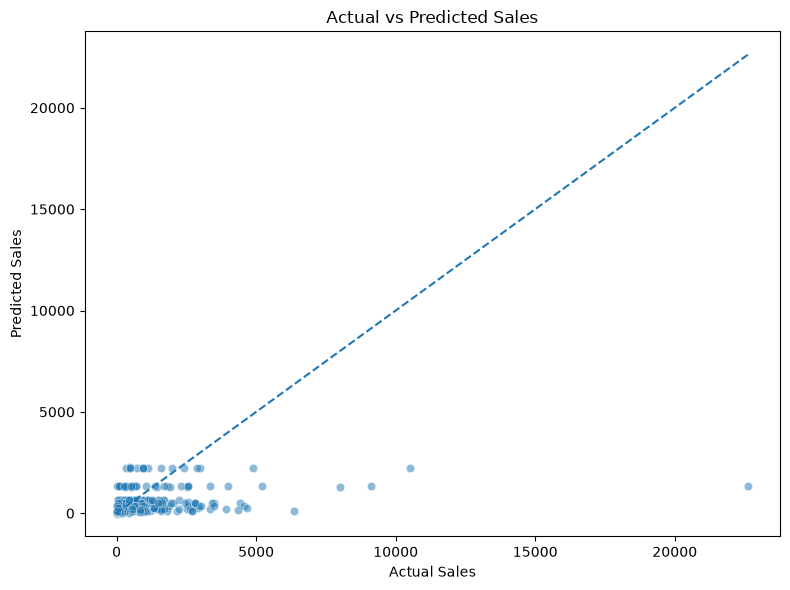

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_test,
    y=y_pred,
    alpha=0.5
)

#Reference line: perfect predictions
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales")
plt.tight_layout()
plt.show()
